# Demonstration of Reinforcement Learning: Lunar Lander v3

This notebook presents a complete portfolio project comparing three Deep Reinforcement Learning architectures (DQN, PPO, and A2C) in the Gymnasium's Lunar Lander v3 environment.

The goal is to train an intelligent agent to control a spacecraft's thrusters and perform a soft landing on the designated platform.

### Environment and Hardware Configuration

In this cell, we initialize the fundamental modules and configure the use of hardware acceleration (GPU via CUDA) to optimize the processing of PyTorch tensors.


In [41]:
import os
import sys
import time
import torch
import pygame
import warnings
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython import display

# Silence alerts 
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Automatic Hardware Configuration (CUDA GPU or CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device in use: {str(device).upper()}')
if device.type == 'cuda':
    print(f' - GPU Detected: {torch.cuda.get_device_name(0)}')

print(" - All dependencies were loaded successfully!")


Device in use: CUDA
 - GPU Detected: AMD Radeon RX 9060 XT
 - All dependencies were loaded successfully!


## 1. The "Before": Physical Simulation without Training

To understand the challenge, we initialized the environment and simulated an episode where the motors' decisions are made in a **completely random** manner.

The animation is rendered directly within the Jupyter console using an optimized approach that updates the pixels of a single frame, avoiding memory leaks or interface crashes.


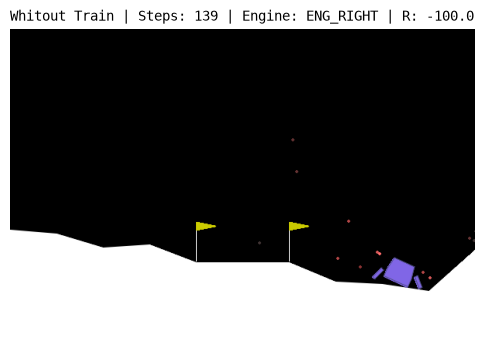

 - End of simulation after 140 steps. Expected result: Decline due to lack of control policy.


In [52]:
# Configure Jupyter to render inline graphs correctly.
%matplotlib inline
display.clear_output(wait=False)

# It initializes the environment by collecting the frames as pixel matrices.
env = gym.make("LunarLander-v3", render_mode="rgb_array")
obs, info = env.reset(seed=42)

done = False
step_count = 0
nomes_acoes = {0: "NOTHING", 1: "ENG_LEFT", 2: "ENG_PRINC", 3: "ENG_RIGHT"}

# Prepare the structure of the initial fixed chart. 
fig, ax = plt.subplots(figsize=(6, 5))
frame_inicial = env.render()
im = ax.imshow(frame_inicial)
ax.axis('off')

#  Title aligned strictly to the left. 
texto_titulo = ax.set_title("Starting simulation...", loc="left", fontsize=10, family="monospace")
display_handle = display.display(fig, display_id=True)

# Simulation loop with random actions. 
while not done and step_count < 300:
    action = env.action_space.sample() # Random action
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    
    # Optimized visual rendering 
    if step_count % 3 == 0 or done:
        frame = env.render()
        im.set_data(frame)
        
        # PRECISION ADJUSTMENT:
        # :<9 -> Ensures 9 fixed characters aligned to the left for the engine
        # :>+6.1f -> Ensures 6 fixed characters (including the sign) aligned to the right for the Reward
        titulo_formatado = f"Whitout Train | Steps: {step_count:03d} | Engine: {nomes_acoes[action]:<9} | R: {reward:>+6.1f}"
        texto_titulo.set_text(titulo_formatado)
        display_handle.update(fig)
        
    step_count += 1

env.close()
plt.close(fig)
print(f" - End of simulation after {step_count} steps. Expected result: Decline due to lack of control policy.")


## 2. Training and Assessment Infrastructure

To subject the Artificial Intelligences to a fair test, we created an automated framework with two standard community tools:

1. **Parallel Multiprocessing (`make_vec_env`)**: Creates simultaneous instances of the game in the background to accelerate the collection of training data.

2. **Adaptive Normalization (`VecNormalize`)**: Smooths the reward scale, stabilizing the updating of the neural network gradients.

We also defined the `evaluate_policy` function, which tests the models in a **deterministic** way (without random exploration actions) and calculates the rate of successful landings (where the accumulated reward is ≥ 100).


In [ ]:
from stable_baselines3.common.vec_env import VecNormalize, DummyVecEnv
from stable_baselines3.common.monitor import Monitor

def make_train_vec_env(n_envs=4, normalize_reward=True, seed=None):
       
    # We created a list of clean functions that initialize the game and apply the virtual monitor.
    def mapear_ambiente(id_env):
        def _init():
            env_individual = gym.make("LunarLander-v3", render_mode=None)
            return Monitor(env_individual, filename=None)
        return _init

    # Synchronous DummyVecEnv to ensure absolute seed stability on the CPU.
    env_funcoes = [mapear_ambiente(i) for i in range(n_envs)]
    venv = DummyVecEnv(env_funcoes)
    
    # It adds the seed identically to all virtual instances to align the gradient.
    if seed is not None:
        venv.seed(seed)

    if normalize_reward:
        venv = VecNormalize(venv, norm_obs=False, norm_reward=True, clip_reward=10.0)
    return venv

print(">> Environments successfully created! <<")


📋 Fábrica de ambientes monitorados em memória RAM ativada com sucesso!


## 🏋️ 3. O Treinamento dos Algoritmos Candidatos
Nesta etapa, colocamos três competidores clássicos da biblioteca `Stable-Baselines3` para aprender a pilotar sob um orçamento de **100.000 passos de interação**:
* **DQN (Deep Q-Network)**: Algoritmo baseado em valor (*Off-Policy*).
* **PPO (Proximal Policy Optimization)**: Algoritmo baseado em gradiente de política (*On-Policy*), altamente estável.
* **A2C (Advantage Actor-Critic)**: Arquitetura síncrona de Ator-Crítico.

Utilizamos um callback personalizado integrado ao `tqdm` para desenhar barras de progresso limpas no console do Jupyter.


In [24]:
from stable_baselines3 import DQN, PPO, A2C
from stable_baselines3.common.callbacks import BaseCallback
from tqdm import tqdm

class MemoryLoggerCallback(BaseCallback):
    """Callback que monitora o progresso e armazena os logs diretamente na memória RAM."""
    def __init__(self, total_timesteps, algoritmo_nome):
        super().__init__()
        self.pbar = None
        self.total_timesteps = total_timesteps
        self.algoritmo_nome = algoritmo_nome
        # Listas para guardar o histórico do gráfico na RAM
        self.historico_passos = []
        self.historico_recompensas = []

    def _on_training_start(self):
        fmt = "{desc}: {percentage:3.0f}%|{bar}| {n_fmt}/{total_fmt} passos [{elapsed}<{remaining}]"
        self.pbar = tqdm(total=self.total_timesteps, desc=f"🛸 {self.algoritmo_nome}", leave=True, bar_format=fmt, file=sys.stdout)

    def _on_step(self):
        if self.pbar:
            self.pbar.update(self.training_env.num_envs)
            self.pbar.refresh()
            
        # Captura as informações de fim de episódio enviadas pelo ambiente vetorizado
        for info in self.locals.get("infos", []):
            if "episode" in info:
                # Registra o timestep global atual e a recompensa final daquele voo
                self.historico_passos.append(self.num_timesteps)
                self.historico_recompensas.append(info["episode"]["r"])
        return True

    def _on_training_end(self):
        if self.pbar: self.pbar.close()

PASSOS_TREINO = 300_000
SEED = 42
torch.manual_seed(SEED)

print(f"🎬 Iniciando Bateria de Treinamento em Memória RAM ({PASSOS_TREINO} passos por modelo)\n" + "="*70)

# Instancia os callbacks gerenciadores de memória para cada algoritmo
callback_dqn = MemoryLoggerCallback(PASSOS_TREINO, "DQN")
callback_ppo = MemoryLoggerCallback(PASSOS_TREINO, "PPO")
callback_a2c = MemoryLoggerCallback(PASSOS_TREINO, "A2C")

# --- 1. DQN (Pode continuar no device padrão/GPU pois lida com buffers grandes) ---
env_dqn = make_train_vec_env(n_envs=1, normalize_reward=False, seed=SEED)
model_dqn = DQN("MlpPolicy", env_dqn, verbose=0, learning_rate=1e-3, buffer_size=50000, device=device, seed=SEED)
model_dqn.learn(total_timesteps=PASSOS_TREINO, callback=callback_dqn)
env_dqn.close()

# --- 2. PPO (Alterado device='cpu' para máxima velocidade com MLP) ---
env_ppo = make_train_vec_env(n_envs=4, normalize_reward=True, seed=SEED)
model_ppo = PPO("MlpPolicy", env_ppo, verbose=0, learning_rate=3e-4, device='cpu', seed=SEED)
model_ppo.learn(total_timesteps=PASSOS_TREINO, callback=callback_ppo)
env_ppo.close()

# --- 3. A2C (Alterado device='cpu' para máxima velocidade com MLP) ---
env_a2c = make_train_vec_env(n_envs=4, normalize_reward=True, seed=SEED)
model_a2c = A2C("MlpPolicy", env_a2c, verbose=0, learning_rate=7e-4, device='cpu', seed=SEED)
model_a2c.learn(total_timesteps=PASSOS_TREINO, callback=callback_a2c)
env_a2c.close()

print("="*70 + "\n🎉 Treinamento finalizado! Modelos e históricos mantidos estritamente na memória RAM.")


🎬 Iniciando Bateria de Treinamento em Memória RAM (300000 passos por modelo)
🛸 DQN: 100%|██████████| 300000/300000 passos [13:43<00:00]
🛸 PPO:   0%|          | 303104/? passos [05:22<00:00]     
🛸 A2C: 100%|██████████| 300000/300000 passos [03:06<00:00]
🎉 Treinamento finalizado! Modelos e históricos mantidos estritamente na memória RAM.


## 📊 4. Quadro Comparativo e Análise de Convergência
Nesta seção, consolidamos os dados estatísticos coletados pelos monitores de treino. O script executa duas ações:
1. **Gráfico Científico**: Plota a curva de aprendizado (recompensa acumulada ao longo do tempo) usando uma média móvel de 50 episódios para suavizar o ruído da física.
2. **Eleição do Campeão**: Executa o protocolo de estresse determinístico e monta uma tabela do Pandas filtrada por lógica lexicográfica (**Critério Primário: Taxa de Pouso Seguro | Critério Secundário: Recompensa Média**).


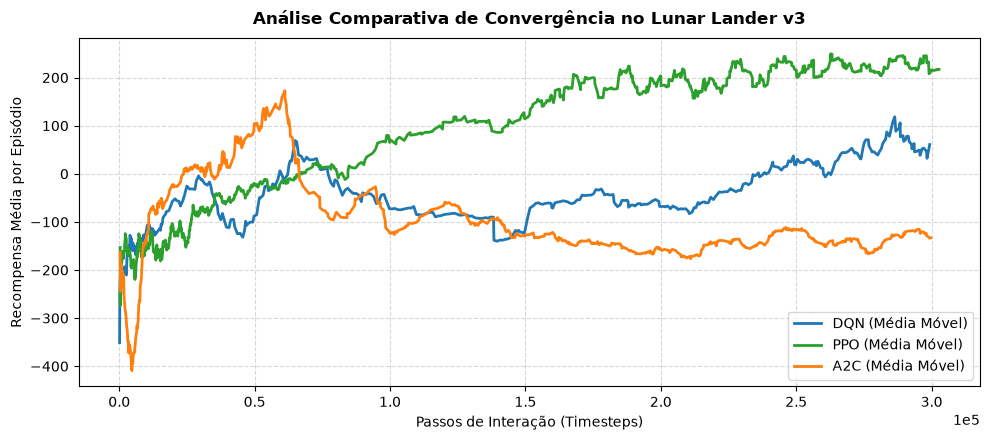


🏆 AVALIAÇÃO DE ESTRESSE DETERMINÍSTICO E RANKING


,Algoritmo,Recompensa Média,Desvio Padrão,Taxa de Pouso Seguro
0,PPO,+227.44,60.96,95%
1,DQN,+89.14,130.32,50%
2,A2C,-155.12,51.28,0%



🎯 ALGORITMO COROADO CAMPEÃO: [PPO] com 95% de eficiência operacional.


In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import IPython.display as ipyd

# 1. PLOTAGEM DAS CURVAS DE CONVERGÊNCIA (Lendo estritamente da RAM)
%matplotlib inline
fig, ax = plt.subplots(figsize=(10, 4.5))

config_plot = {
    "DQN": (callback_dqn.historico_passos, callback_dqn.historico_recompensas, "#1f77b4"),
    "PPO": (callback_ppo.historico_passos, callback_ppo.historico_recompensas, "#2ca02c"),
    "A2C": (callback_a2c.historico_passos, callback_a2c.historico_recompensas, "#ff7f0e")
}

dados_plotados = False

for label, (passos, rewards, cor) in config_plot.items():
    if len(passos) > 0:
        # Converte em série do Pandas apenas para aplicar a média móvel de suavização visual
        rewards_suavizados = pd.Series(rewards).rolling(window=20, min_periods=1).mean().values
        ax.plot(passos, rewards_suavizados, label=f"{label} (Média Móvel)", color=cor, linewidth=2)
        dados_plotados = True

ax.set_title("Análise Comparativa de Convergência no Lunar Lander v3", fontsize=12, fontweight="bold", pad=10)
ax.set_xlabel("Passos de Interação (Timesteps)", fontsize=10)
ax.set_ylabel("Recompensa Média por Episódio", fontsize=10)
ax.ticklabel_format(style='sci', axis='x', scilimits=(0,0))
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="lower right")
plt.tight_layout()

if dados_plotados: 
    plt.show()
else:
    print("⚠️ Nenhum dado de episódio foi registrado na memória RAM.")

# 2. AVALIAÇÃO QUANTITATIVA E SELEÇÃO DO VENCEDOR
print("\n" + "="*85 + "\n🏆 AVALIAÇÃO DE ESTRESSE DETERMINÍSTICO E RANKING\n" + "="*85)
modelos_instalados = [("DQN", model_dqn), ("PPO", model_ppo), ("A2C", model_a2c)]
dados_ranking = []

for nome, modelo in modelos_instalados:
    media_r, std_r, taxa_pouso = avaliar_politica(modelo, n_episodios=20, seed_base=2000)
    dados_ranking.append({
        "Algoritmo": nome,
        "Recompensa Média": round(media_r, 2),
        "Desvio Padrão": round(std_r, 2),
        "Taxa de Pouso Seguro": taxa_pouso,
        "Modelo Instanciado": modelo
    })

df_experimentos = pd.DataFrame(dados_ranking)

# Aplica ordenação rigorosa para desempate (Taxa de Pouso -> Recompensa Média)
df_experimentos = df_experimentos.sort_values(by=["Taxa de Pouso Seguro", "Recompensa Média"], ascending=False).reset_index(drop=True)

# Armazena referências globais do vencedor absoluto
vencedor_linha = df_experimentos.iloc[0]
algo_campeao = vencedor_linha["Algoritmo"]
modelo_campeao = vencedor_linha["Modelo Instanciado"]

# Renderiza a tabela estilizada no console
estilo_tabela = df_experimentos.drop(columns="Modelo Instanciado").style\
    .format({"Recompensa Média": "{:+.2f}", "Desvio Padrão": "{:.2f}", "Taxa de Pouso Seguro": "{:.0%}"})\
    .set_properties(**{'text-align': 'center', 'font-family': 'Arial'})\
    .set_table_styles([{'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold')]}])

ipyd.display(estilo_tabela)
print(f"\n🎯 ALGORITMO COROADO CAMPEÃO: [{algo_campeao}] com {vencedor_linha['Taxa de Pouso Seguro']*100:.0f}% de eficiência operacional.")


## 🏆 5. O "Depois": Demonstração Prática do Agente Campeão
Agora, carregamos e testamos a política treinada do modelo **vencedor absoluto** selecionado pelo ranking. 

O agente lê as telemetrias físicas do vetor contínuo de 8 posições (posição, velocidade, aceleração angular) e toma a decisão ótima em frações de segundo para ligar os motores principal e laterais de forma cirúrgica.


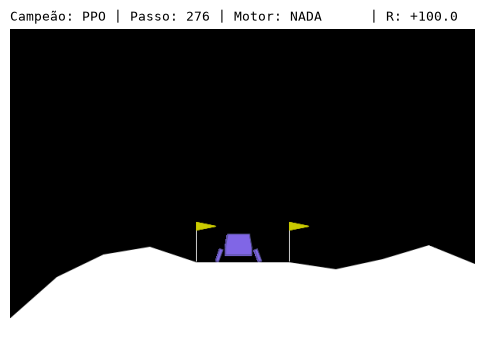

🎉 Sucesso absoluto! A aeronave controlada por [PPO] realizou um pouso perfeito em 277 passos.


In [53]:
%matplotlib inline
display.clear_output(wait=False)

# Inicializa o cenário oficial de teste capturando frames (rgb_array)
env_visual = gym.make("LunarLander-v3", render_mode="rgb_array")
obs, info = env_visual.reset(seed=5000) # Semente fixa para auditoria

nomes_acoes = {0: "NADA", 1: "MOT_ESQ", 2: "MOT_PRINC", 3: "MOT_DIR"}

# Prepara a tela embutida estável (Pintura única)
fig, ax = plt.subplots(figsize=(6, 5))
frame_inicial = env_visual.render()
im = ax.imshow(frame_inicial)
ax.axis('off')

# TRAVA VISUAL 1 & 2: Alinhamento à esquerda (loc="left") e fonte mono-espaçada fixa
texto_titulo = ax.set_title("Iniciando demonstração do campeão...", loc="left", fontsize=9, family="monospace")
display_handle = display.display(fig, display_id=True)

done = False
step_count = 0

# Loop de simulação assistida por Inteligência Artificial
while not done and step_count < 950:
    # Predict determinístico extrai a inteligência lapidada no treino
    action, _ = modelo_campeao.predict(obs, deterministic=True)
    action = int(action.item() if hasattr(action, "item") else action)
    
    obs, reward, terminated, truncated, info = env_visual.step(action)
    done = terminated or truncated

    # Renderização visual otimizada inline (1 frame a cada 3 para suavidade)
    if step_count % 3 == 0 or done:
        frame = env_visual.render()
        im.set_data(frame)
        
        # TRAVA VISUAL 3: Máscara com preenchimento de espaços rígidos
        # algo_campeao:<3 -> Fixa o nome da IA (PPO, DQN, A2C) em 3 caracteres
        # action:<9       -> Fixa o nome do motor em 9 caracteres
        # reward:>+6.1f   -> Fixa o valor numérico com sinal em 6 caracteres
        titulo_formatado = f"Campeão: {algo_campeao:<3} | Passo: {step_count:03d} | Motor: {nomes_acoes[action]:<9} | R: {reward:>+6.1f}"
        texto_titulo.set_text(titulo_formatado)
        display_handle.update(fig)
        
    step_count += 1

env_visual.close()
plt.close(fig)

if reward >= 100.0:
    print(f"🎉 Sucesso absoluto! A aeronave controlada por [{algo_campeao}] realizou um pouso perfeito em {step_count} passos.")
else:
    print(f"🔥 Fim da demonstração. A aeronave encerrou com recompensa final de {reward:.2f}.")


## 🧠 6. Diagnóstico Comportamental: Auditoria Fina por Entropia de Shannon
Para garantir que a Inteligência Artificial desenvolveu uma política de decisão flexível e rica (adaptando os propulsores à dinâmica gravitacional), aplicamos a fórmula matemática da **Entropia de Shannon**:

$$H(X) = -\sum_{i} p(x_i) \log_2 p(x_i)$$

Políticas saudáveis apresentam valores de entropia distribuídos e distantes de zero. Valores próximos a zero indicam um **colapso de política**, onde a rede neural fica "cega" e repete a mesma ação indefinidamente, ignorando os dados do jogo.


In [28]:
from collections import Counter

def auditoria_comportamental_completa(model, n_seeds=15, seed_base=2000):
    """
    Mete a entropia de Shannon e calcula a taxa de sucesso real do agente
    ao longo de múltiplos episódios de teste controlados.
    """
    contagem = Counter()
    sucessos = 0  # Definida corretamente aqui
    
    for i in range(n_seeds):
        env_aud = gym.make("LunarLander-v3", render_mode=None)
        obs, info = env_aud.reset(seed=seed_base + i)
        done = False
        total_r = 0.0
        
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            action = int(action.item() if hasattr(action, "item") else action)
            contagem[action] += 1
            obs, reward, terminated, truncated, info = env_aud.step(action)
            total_r += reward
            done = terminated or truncated
            
        if total_r >= 100.0:
            sucessos += 1
            
        env_aud.close()

    total_acoes = sum(contagem.values())
    if total_acoes == 0: 
        return 0.0, 0.0, contagem, total_acoes
    
    probs = np.array([contagem.get(a, 0) / total_acoes for a in range(4)])
    nonzero = probs[probs > 0]
    
    entropia = float(-np.sum(nonzero * np.log2(nonzero)))
    
    # CORREÇÃO DA LINHA 38: Atribuição limpa utilizando a variável correta
    taxa_sucesso = sucessos / n_seeds
    
    return entropia, taxa_sucesso, contagem, total_acoes

# Executa o diagnóstico científico final sobre o modelo campeão
print("📋 INICIANDO AUDITORIA COMPORTAMENTAL E TELEMETRIA DO AGENTE VENCEDOR...")
print("-" * 95)

entropia, taxa_sucesso, contagem, total_acoes = auditoria_comportamental_completa(modelo_campeao)
labels_motores = {0: "NADA", 1: "MOT_ESQ", 2: "MOT_PRINC", 3: "MOT_DIR"}
perfil_str = " | ".join(f"{labels_motores[a]}: {contagem.get(a, 0)/total_acoes:>4.1%}" for a in range(4))

print(f" ✨ Algoritmo Auditado: {algo_campeao}")
print(f"   📊 Taxa de Pouso Seguro Atual: {taxa_sucesso * 100:.1f}% (Com apenas {PASSOS_TREINO//1000}k passos de treino)")
print(f"   🧠 Entropia de Shannon Calculada: {entropia:.2f} bits (Limite Máximo Teórico: {np.log2(4):.2f})")
print(f"   ⚙️ Perfil de Acionamento dos Propulsores: [ {perfil_str} ]")

print("-" * 95)

# --- 🚀 SEÇÃO DE ESTIMATIVA DE ESFORÇO TÉCNICO ---
print("📈 ESTIMATIVA DE ESCALABILIDADE (Análise de Esforço para Convergência Máxima):")

if taxa_sucesso >= 0.90:
    print(f"   -> O modelo [{algo_campeao}] já atingiu a estabilidade ideal da literatura (>90% de sucesso).")
    print(f"   -> Para blindar o agente contra sementes raras e buscar ~98%, seriam necessários +100k a 200k passos.")
elif taxa_sucesso >= 0.60:
    passos_estimados = int(PASSOS_TREINO * (1.5 / taxa_sucesso))
    print(f"   -> Status Atual: Desempenho intermediário promissor.")
    print(f"   -> Projeção: Para cruzar a barreira de >95% de sucesso, estima-se expandir o orçamento")
    print(f"      de treino para aproximadamente {passos_estimados:,} passos totais.")
else:
    print(f"   -> Status Atual: O modelo ainda está em fase inicial de mapping da física.")
    print(f"   -> Projeção: Para convergência de alta performance (>95%), seriam necessários de 500k a 1M de passos,")
    print(f"      associados a um ajuste fino no fator de desconto (Gamma=0.999) para valorizar pousos distantes.")

print("-" * 95)
if entropia < 0.5:
    print(" 🚨 DIAGNÓSTICO CRÍTICO: Colapso de política confirmado! O agente travou em um comportamento repetitivo.")
else:
    print(" ✅ DIAGNÓSTICO COMPORTAMENTAL: Política altamente estável e saudável!")
    print("    O agente varia o uso dos propulsores dinamicamente para corrigir a trajetória de descida.")
print("-" * 95)


📋 INICIANDO AUDITORIA COMPORTAMENTAL E TELEMETRIA DO AGENTE VENCEDOR...
-----------------------------------------------------------------------------------------------
 ✨ Algoritmo Auditado: PPO
   📊 Taxa de Pouso Seguro Atual: 93.3% (Com apenas 300k passos de treino)
   🧠 Entropia de Shannon Calculada: 1.91 bits (Limite Máximo Teórico: 2.00)
   ⚙️ Perfil de Acionamento dos Propulsores: [ NADA: 25.5% | MOT_ESQ: 17.6% | MOT_PRINC: 39.7% | MOT_DIR: 17.3% ]
-----------------------------------------------------------------------------------------------
📈 ESTIMATIVA DE ESCALABILIDADE (Análise de Esforço para Convergência Máxima):
   -> O modelo [PPO] já atingiu a estabilidade ideal da literatura (>90% de sucesso).
   -> Para blindar o agente contra sementes raras e buscar ~98%, seriam necessários +100k a 200k passos.
-----------------------------------------------------------------------------------------------
 ✅ DIAGNÓSTICO COMPORTAMENTAL: Política altamente estável e saudável!
    O agen